# Bayesian GARCH: From Volatility Forecasting to Portfolio Allocation
**Kang Yu** · Erdős Institute, Quantitative Methods in Finance · Fall 2026 · *concise walkthrough (recommended starting point)*

## 1. Research question and motivation

> **Research question.** Does accounting for Bayesian parameter uncertainty improve conditional variance forecasts,
> predictive return distributions, and investment performance?

**Motivation.**
- **Volatility clusters.** Returns are almost unpredictable, but the *size* of tomorrow's move is predictable; GARCH(1,1)
  is the standard model for this.
- **Parameters are uncertain.** GARCH's three parameters are estimated from a few noisy years, yet the usual
  maximum-likelihood (MLE) forecast treats them as exact. A Bayesian posterior carries that uncertainty into the forecast.
- **Returns are heavy-tailed,** so the shape of the predictive distribution matters, not only its variance.
- **A variance is not a distribution.** Two forecasts with the same variance can give very different crash probabilities.
- **A statistical gain is not an economic gain.** A strategy can look safer simply because it holds less risk.

| | Hypothesis | Metric | Section |
|---|---|---|---|
| **H1** | Bayesian integration improves one-day-ahead **conditional variance** forecasts relative to Gaussian GARCH MLE | QLIKE | §7 |
| **H2** | It improves the **predictive distribution** of daily returns | log predictive score | §8 |
| **H3** | Posterior uncertainty in volatility targeting gives **better investment outcomes, beyond holding less risk** | Sharpe, drawdown, exposure-matched control | §9–§10 |

**Narrative.** research question → data → GARCH and MLE → Bayesian GARCH → Student-$t$ GARCH → rolling design →
**H1** → **H2** → **H3** → limitations → summary. Each hypothesis section answers: *what is the question, how is it
investigated, which metric and why, what do the numbers show, what can be concluded.* Two results are highlighted:
**Student-$t$ GARCH versus Bayesian integration** (§8) and the **exposure-matched MLE control** (§10).

**How results were obtained.** Every computation is labelled:

| Label | Meaning |
|---|---|
| 🟢 **direct** | computed here from prices, rates, or a model fitted live in this notebook |
| 🔵 **saved forecasts** | recomputed here from the saved *daily* forecasts or posterior draws of the full rolling experiment (320 refits, checksum-verified) |
| ⚪ **artifact** | a saved research output shown without recomputation |

`check(...)` lines print PASS/FAIL against the validated research results. The comprehensive notebook
`walkthrough.ipynb` derives every step in more depth; this notebook is self-contained. Runtime: about 30–40 s.

In [1]:
import sys, time, zlib, warnings
from pathlib import Path
T0 = time.time()
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists() and (p / 'src' / 'bgarch').is_dir())
sys.path.insert(0, str(ROOT / 'src'))   # works from notebooks/ and course/notebooks/; harmless after `pip install -e .`
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import norm
from IPython.display import display

from bgarch import data, garch, bayes, forecast as fc, student_t as tg, ewma, evaluation as ev, diagnostics as dg, portfolio as pf
from bgarch_experiments import config as cfg, tables, strategies, adequacy as A, notebook as N
from bgarch_experiments.artifacts import verify_manifest
%matplotlib inline
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160); pd.set_option('display.precision', 4)
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']; GREY, INK = '#6b6a63', '#1f1f1e'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3dc', 'axes.axisbelow': True, 'legend.frameon': False})
RAW, FC, ART = N.RAW, N.FORECASTS, N.ARTIFACT
check = N.Checks()
STORE = tables.Store(cfg.SAVED_FORECASTS); tables.use_store(STORE)
ASSETS, WINDOWS, SEGS = data.ASSETS, cfg.WINDOWS, cfg.SEGS
SEGL = {'ext': '2017–22 (primary)', 'test': '2023–26 (inspected)'}
check('saved rolling-experiment files match their SHA-256 checksums', verify_manifest() == 48, '48 files', ART)
check('saved posterior-draw files match their SHA-256 checksums', A.verify_manifest() == 16, '16 files', ART)

PASS  saved rolling-experiment files match their SHA-256 checksums  [48 files]
PASS  saved posterior-draw files match their SHA-256 checksums  [16 files]


## 2. Financial data and volatility clustering

**Assets.** Four exchange-traded funds (ETFs) that cover different risks: **SPY** (S&P 500 equities), **QQQ**
(Nasdaq-100, technology-heavy equities), **TLT** (US Treasury bonds with 20+ years to maturity, i.e. interest-rate
risk) and **GLD** (gold). Cash earns the effective federal funds rate (FRED series DFF).

**Prices and returns.** *Adjusted* closing prices include dividends and splits, so they measure total return. Prices
trend and are non-stationary, so we model the daily **log return**
$$r_t=\log\!\left(\frac{P_t}{P_{t-1}}\right),$$
which is approximately the percentage change and adds up over time. **Variance** $h_t$ is the daily conditional
variance; **volatility** is its square root, quoted *annualised* as $\sqrt{252\,h_t}$ (252 trading days per year).

🟢 *direct* — computed from the adjusted closes in `data/` (not redistributed; see the repository README).

In [2]:
prices = pd.DataFrame({a: data.load_prices(a) for a in ASSETS})
rets = data.all_returns()                                   # r_t = log(P_t / P_{t-1})
check('returns are log price ratios', np.allclose(rets.SPY.to_numpy(), np.diff(np.log(prices.SPY.to_numpy()))), level=RAW)
print(f'{len(rets)} daily returns, {rets.index[0].date()} to {rets.index[-1].date()}')
display(pd.DataFrame({'annualised volatility': rets.std() * np.sqrt(252), 'skewness': rets.skew(),
                      'excess kurtosis': rets.kurt(), 'worst day': rets.min()}).round(3))

PASS  returns are log price ratios
3481 daily returns, 2013-01-03 to 2026-11-04


,annualised volatility,skewness,excess kurtosis,worst day
SPY,0.167,-0.587,15.144,-0.116
QQQ,0.209,-0.400,7.946,-0.128
TLT,0.144,-0.044,4.368,-0.069
GLD,0.167,-0.705,7.639,-0.108


**Stylised facts that motivate GARCH.** (i) Large moves cluster in time; (ii) returns are almost uncorrelated, but
*squared* returns are strongly and persistently correlated, so the *size* of tomorrow's move is predictable even if
its direction is not; (iii) returns have far heavier tails than a normal distribution.

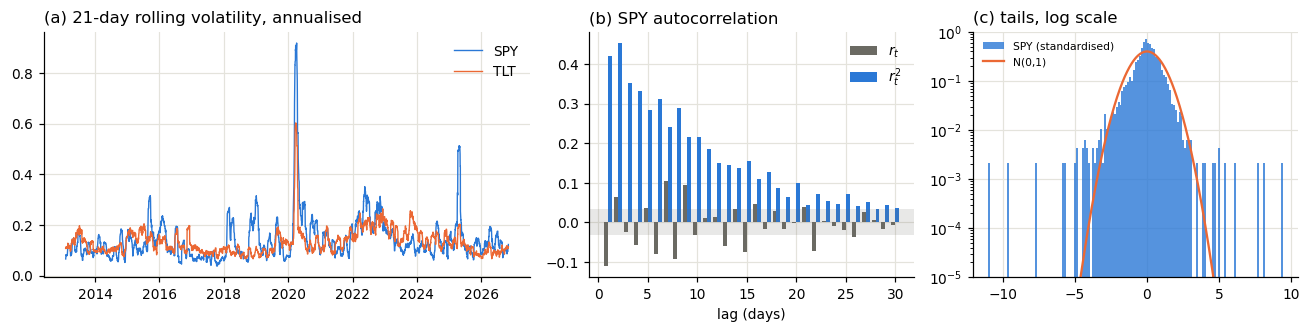

SPY lag-1 autocorrelation: returns -0.111, squared returns +0.421;  days beyond 3 sd: 45 vs 9.4 expected under normality


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.1), gridspec_kw={'width_ratios': [1.5, 1, 1]})
ax[0].plot(rets.index, dg.realized_vol(rets.SPY.to_numpy()), color=C[0], lw=.9, label='SPY')
ax[0].plot(rets.index, dg.realized_vol(rets.TLT.to_numpy()), color=C[1], lw=.9, label='TLT')
ax[0].set_title('(a) 21-day rolling volatility, annualised', loc='left'); ax[0].legend()
L = 30
ax[1].bar(np.arange(1, L + 1) - .2, dg.acf(rets.SPY, L), .4, color=GREY, label='$r_t$')
ax[1].bar(np.arange(1, L + 1) + .2, dg.acf(rets.SPY ** 2, L), .4, color=C[0], label='$r_t^2$')
ax[1].axhspan(-1.96 / np.sqrt(len(rets)), 1.96 / np.sqrt(len(rets)), color=GREY, alpha=.15, lw=0)
ax[1].set_title('(b) SPY autocorrelation', loc='left'); ax[1].set_xlabel('lag (days)'); ax[1].legend()
z = (rets.SPY - rets.SPY.mean()) / rets.SPY.std(); x = np.linspace(-8, 8, 400)
ax[2].hist(z, bins=150, density=True, color=C[0], alpha=.8, label='SPY (standardised)')
ax[2].plot(x, norm.pdf(x), color=C[1], label='N(0,1)'); ax[2].set_yscale('log'); ax[2].set_ylim(1e-5, 1)
ax[2].set_title('(c) tails, log scale', loc='left'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"SPY lag-1 autocorrelation: returns {dg.acf(rets.SPY, 1)[0]:+.3f}, squared returns {dg.acf(rets.SPY**2, 1)[0]:+.3f};  "
      f"days beyond 3 sd: {int((np.abs(z) > 3).sum())} vs {2*norm.sf(3)*len(z):.1f} expected under normality")

**Interpretation.** Panel (a): volatility moves in persistent regimes (2020, 2022). Panel (b): the bars for $r_t$ sit
inside the grey noise band, while those for $r_t^2$ stay positive for weeks; this persistence is exactly what GARCH
models. Panel (c): the normal density badly underestimates extreme days. A model with *time-varying variance* explains
part of these fat tails; the rest is a question of the innovation distribution, which becomes the central issue in §8.
The 21-day rolling volatility is a *descriptive* backward-looking statistic, not a forecast.

## 3. Gaussian GARCH(1,1) and classical estimation

**Model.** With $\mathcal F_{t-1}$ the information up to day $t-1$,
$$r_t=\sqrt{h_t}\,z_t,\quad z_t\overset{iid}{\sim}N(0,1),\qquad h_t=\operatorname{Var}(r_t\mid\mathcal F_{t-1})=\omega+\alpha\,r_{t-1}^2+\beta\,h_{t-1}.$$
The conditional mean is set to zero (daily means are negligible relative to volatility).

| Parameter | Meaning |
|---|---|
| $\alpha$ | **reaction**: how much yesterday's surprise $r_{t-1}^2$ raises today's variance |
| $\beta$ | **memory**: how much of yesterday's variance carries over |
| $p=\alpha+\beta$ | **persistence**: a shock's excess variance decays like $p^k$; half-life $\ln 0.5/\ln p$ days |
| $V=\omega/(1-p)$ | **long-run variance** to which forecasts revert |

Positivity needs $\omega>0$, $\alpha,\beta\ge0$; covariance stationarity needs $p<1$. The filter starts at $h_1=V$.
Because $h_t$ depends only on past data, the **one-step-ahead forecast** for tomorrow is available after today's close.

**Likelihood.** Conditionally on the past, $r_t\sim N(0,h_t)$, so the log-likelihood is evaluated recursively by
running the filter once:
$$\ell(\theta)=-\tfrac12\sum_{t=1}^{T}\Big[\log 2\pi+\log h_t(\theta)+\frac{r_t^2}{h_t(\theta)}\Big].$$

**Numerical strategy.** The constraints are awkward for an optimiser, so the implementation works in unconstrained
coordinates $u=(\log V,\ \operatorname{logit}p,\ \operatorname{logit}q)$ with $q=\alpha/p$. Every $u\in\mathbb R^3$ maps
back to a valid model: $p=\operatorname{expit}(u_2)$, $q=\operatorname{expit}(u_3)$, $\alpha=pq$, $\beta=p(1-q)$,
$\omega=V(1-p)$. `garch.mle_fit` maximises $\ell$ by **L-BFGS-B from several starting points** inside box bounds
(including $p\le\operatorname{expit}(7)=0.99909$), with a Powell fallback, and keeps the best solution. The recursion
is compiled with numba.

**Representative fit (🟢 direct).** SPY, the 500 trading days before 2023-01-03, the first refit of the 2023–26 period.

In [4]:
r_spy = data.log_returns('SPY'); RR = r_spy.to_numpy()
st = int(r_spy.index.searchsorted(pd.Timestamp('2023-01-01'))); W = 500
train = RR[st - W:st]                                       # estimation window: returns strictly before the forecast day
t0 = time.perf_counter(); u_hat, fit = garch.mle_fit(train); t_mle = time.perf_counter() - t0
om, al, be = garch.to_natural(u_hat); p_hat = al + be
h_next = garch.next_variance(train, u_hat)                  # one-step-ahead forecast for 2023-01-03
display(pd.Series({'omega': om, 'alpha': al, 'beta': be, 'persistence p': p_hat, 'half-life (days)': garch.half_life(p_hat),
                   'long-run ann. vol': np.sqrt(252 * om / (1 - p_hat)), 'max log-likelihood': -fit.fun, 'converged': fit.success,
                   'next-day ann. vol': np.sqrt(252 * h_next), 'seconds': t_mle}, name='MLE, SPY').to_frame())
saved = STORE.fits('SPY', 500, 'test').iloc[0]
check('fresh MLE log-likelihood == saved research fit', abs(-fit.fun - saved.mle_loglik) < 1e-8, f'{-fit.fun:.4f}', RAW)
f_spy = STORE.daily('SPY', 500, 'test')
check('fresh next-day forecast == saved forecast for 2023-01-03', np.isclose(h_next, f_spy.variance_mle.iloc[0], rtol=1e-10), level=RAW)

,"MLE, SPY"
omega,0.0
alpha,0.06
beta,0.9318
persistence p,0.9918
half-life (days),83.9191
long-run ann. vol,0.1847
max log-likelihood,1536.0289
converged,True
next-day ann. vol,0.2015
seconds,0.1308


PASS  fresh MLE log-likelihood == saved research fit  [1536.0289]
PASS  fresh next-day forecast == saved forecast for 2023-01-03


**Interpretation.** Persistence is close to one (shocks fade over weeks), which is typical for daily equity data. Near
$p=1$ the likelihood is flat, so $\alpha$, $\beta$ and $V$ are imprecisely determined from 500 days. That imprecision is
what a Bayesian treatment tries to carry into the forecast.

**Limitation (🔵 saved fit logs).** In the full experiment the persistence cap binds in some refits, where the
likelihood would keep rising towards $p=1$:

In [5]:
fits_all = pd.concat([STORE.fits(a, w, s).assign(asset=a, window=w, segment=s) for s in SEGS for a in ASSETS for w in WINDOWS])
n_b = int(fits_all.mle_at_bound.sum())
check('MLE at the persistence bound in 30 of 320 refits (report §2.1)', n_b == 30 and len(fits_all) == 320, f'{n_b} of {len(fits_all)}', FC)
display(fits_all.pivot_table(index='asset', columns=['segment', 'window'], values='mle_at_bound', aggfunc='sum'))

PASS  MLE at the persistence bound in 30 of 320 refits (report §2.1)  [30 of 320]


segment  ext      test     
window  500  1000 500  1000
asset                      
GLD        5    3    0    0
QQQ        0    0    5    0
SPY        0    0    2    0
TLT        4    3    4    4

## 4. Bayesian inference and prediction

**Posterior.** Bayes' theorem combines the likelihood with a prior:
$$p(u\mid r_{1:T})\ \propto\ L(u\mid r_{1:T})\,p(u).$$
The prior is independent normal on the unconstrained coordinates: $\log V\sim N(\log 10^{-4},1.5^2)$,
$\operatorname{logit}p\sim N(\operatorname{logit}0.8,1.5^2)$, $\operatorname{logit}q\sim N(\operatorname{logit}0.1,1.5^2)$.
It is weakly informative: it rules out absurd volatility levels and gently pulls persistence away from exactly one.
*Parameter* uncertainty (what we do not know about $\theta$) is distinct from *return* uncertainty (the randomness of
$z_t$ that remains even if $\theta$ were known).

**Why numerical methods.** The posterior has no closed form, because $h_t(\theta)$ is a nonlinear recursion.

**Random-walk Metropolis (RWM).** From the current state $u$, propose $u^\star=u+\varepsilon$ with
$\varepsilon\sim N(0,\Sigma)$ and accept it with probability
$$a(u,u^\star)=\min\Big\{1,\ \frac{p(u^\star\mid r)}{p(u\mid r)}\Big\}$$
(the proposal is symmetric, so it cancels). Otherwise stay at $u$. Pseudocode: *repeat: propose → compute
log-posterior ratio → accept if* $\log U<\log p(u^\star\mid r)-\log p(u\mid r)$ *→ store the current state.* The
stored states form a Markov chain whose stationary distribution is the posterior.

**Settings used.** 4 chains started from over-dispersed points; 2,500 warm-up iterations in which $\Sigma$ is adapted
towards about 23% acceptance, then frozen; 4,000 retained draws per chain.

**Diagnostics.** *Trace plots* (chains should overlap and mix); *autocorrelation* within chains; *effective sample
size* (ESS, the number of independent draws worth the same precision); *rank-normalised* $\hat R$ (between- versus
within-chain variance, $\approx1$ at convergence); *Monte Carlo standard error* (MCSE $\approx$ sd/$\sqrt{\text{ESS}}$).
A fit passes only if $\hat R<1.01$ and bulk and tail ESS $\ge400$ for every parameter.

**Representative fit (🟢 direct, research seed).**

In [6]:
prior = bayes.PRIORS['moderate']
t0 = time.perf_counter()
chains, meta = bayes.reliable_bayes_fit(train, u_hat, n_chains=4, warmup=2500, draws=4000, seed=2026, log_density=prior.log_posterior)
t_mcmc = time.perf_counter() - t0
diag, passed = bayes.diagnostics(chains); flat = chains.reshape(-1, 3)
print(f'{4*6500:,} log-posterior evaluations in {t_mcmc:.1f} s; acceptance per chain {[round(m["acceptance"], 3) for m in meta]}; '
      f'strict rule passed: {passed}')
display(diag.round(4))
check('posterior mean persistence == saved research fit', abs(expit(flat[:, 1]).mean() - saved.post_mean_persistence) < 1e-12, level=RAW)
post = bayes.posterior_summary(chains); post['MLE'] = [om, al, be, p_hat, om / (1 - p_hat), np.sqrt(252 * om / (1 - p_hat)), al / p_hat, garch.half_life(p_hat)]
display(post.round(5))

26,000 log-posterior evaluations in 0.2 s; acceptance per chain [0.221, 0.237, 0.235, 0.268]; strict rule passed: True


,r_hat,ess_bulk,ess_tail
parameter,,,
u0,1.0016,1459.1016,1954.0525
u1,1.0026,1375.3231,1696.9425
u2,1.0035,1326.6071,1819.6519
V,1.0018,1459.1016,1954.0525
p,1.0026,1375.3231,1696.9425
q,1.0035,1326.6071,1819.6519
omega,1.0026,1349.0830,1512.8517
alpha,1.0036,1325.5459,1822.6219
beta,1.0034,1358.1981,1952.8442


PASS  posterior mean persistence == saved research fit


,mean,sd,q05,q50,q95,MLE
omega,0.0000,0.0000e+00,0.0000e+00,0.0000,1.0000e-05,0.0000
alpha,0.0827,3.1030e-02,4.2780e-02,0.0780,1.4036e-01,0.0600
beta,0.9001,3.8100e-02,8.2997e-01,0.9069,9.4875e-01,0.9318
persistence,0.9829,1.0570e-02,9.6220e-01,0.9851,9.9523e-01,0.9918
long_run_variance,0.0001,4.0000e-05,8.0000e-05,0.0001,2.2000e-04,0.0001
long_run_ann_vol,0.1852,2.8070e-02,1.4623e-01,0.1826,2.3602e-01,0.1847
q,0.0844,3.2300e-02,4.3180e-02,0.0791,1.4424e-01,0.0605
half_life_days,60.6326,5.6855e+01,1.7990e+01,46.1477,1.4508e+02,83.9191


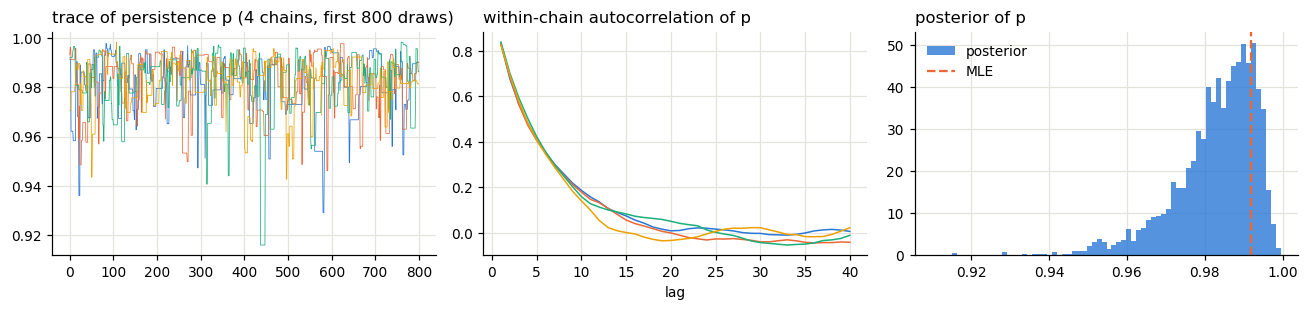

In [7]:
p_ch = expit(chains[:, :, 1])
fig, ax = plt.subplots(1, 3, figsize=(12, 2.9))
for k in range(4):
    ax[0].plot(p_ch[k, :800], lw=.5, color=C[k]); ax[1].plot(np.arange(1, 41), dg.acf(p_ch[k], 40), lw=1, color=C[k])
ax[0].set_title('trace of persistence p (4 chains, first 800 draws)', loc='left')
ax[1].set_title('within-chain autocorrelation of p', loc='left'); ax[1].set_xlabel('lag')
ax[2].hist(p_ch.ravel(), bins=70, density=True, color=C[0], alpha=.8, label='posterior')
ax[2].axvline(p_hat, color=C[1], ls='--', label='MLE'); ax[2].set_title('posterior of p', loc='left'); ax[2].legend()
plt.tight_layout(); plt.show()

**Interpretation.** The chains overlap, autocorrelation dies out within a few dozen draws, and $\hat R\approx1$ with
large ESS, so the posterior is reliably sampled. It is concentrated near the MLE. Across the full experiment, 4 of the
320 refits miss the strict rule marginally (max $\hat R=1.019$); the forecast comparisons are unchanged without them.
MCMC output is random, so Bayesian numbers can differ slightly by seed and platform (about 0.01 in Sharpe ratio later on).

### From posterior draws to forecasts

Each posterior draw $\theta^{(m)}$ runs its own recursion and gives its own forecast $h_{t+1}(\theta^{(m)})$. Because the
forecast is a *nonlinear* function of the parameters, averaging parameters and averaging forecasts differ:

| Forecast | Formula | Used for |
|---|---|---|
| MLE plug-in | $h_{t+1}(\hat\theta)$: one point, treated as exact | baseline |
| posterior-mean plug-in | $h_{t+1}(\bar\theta)$, $\bar\theta=E[\theta\mid D_t]$ | *shrinkage* only |
| posterior-integrated | $\bar h_{t+1}=E[h_{t+1}(\theta)\mid D_t]\approx\frac1M\sum_m h_{t+1}(\theta^{(m)})$ | **H1** |
| predictive mixture | $\frac1M\sum_m N\big(r;0,h_{t+1}(\theta^{(m)})\big)$ | **H2** |
| upper-90 | 90th percentile of $\{h_{t+1}(\theta^{(m)})\}$ | **H3** (deliberately cautious) |

$M=300$ posterior draws are used per refit (🟢 below, recomputed and checked against the saved forecasts).

PASS  fresh variance_bayes_meanplug == saved daily forecast (63 days)
PASS  fresh variance_bayes_integrated == saved daily forecast (63 days)
PASS  fresh variance_bayes_q90 == saved daily forecast (63 days)


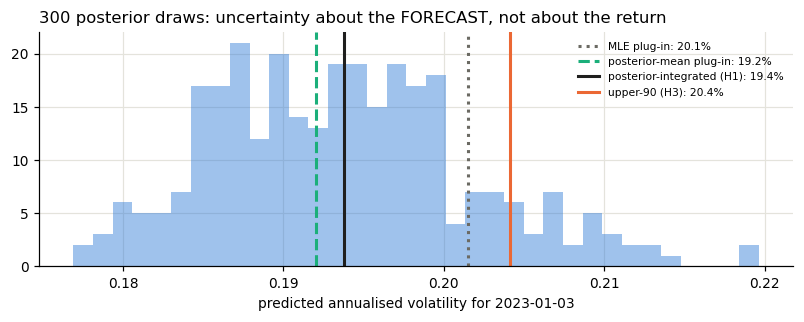

posterior CV of next-day variance 0.082


In [8]:
rng = np.random.default_rng(2026)                            # the research protocol's subsample of M = 300 draws
us = flat[rng.choice(len(flat), size=300, replace=False)]
local = RR[st - W: st + 63]                                  # window + first 63-day forecast block
Hd = fc.variance_draws(local, W, us)                         # (300 draws, 63 days) of one-step variances
s = fc.predictive_summary(Hd); h_mp = garch.variance_path(local, W, bayes.posterior_mean_u(flat)); h_mle = garch.variance_path(local, W, u_hat)
for col, val in [('variance_bayes_meanplug', h_mp), ('variance_bayes_integrated', s['integrated']), ('variance_bayes_q90', s['q90'])]:
    check(f'fresh {col} == saved daily forecast (63 days)', np.allclose(val, f_spy[col].to_numpy()[:63], rtol=1e-10), level=RAW)
v0 = Hd[:, 0]; ann = lambda h: np.sqrt(252 * h)
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.hist(ann(v0), bins=35, color=C[0], alpha=.45)
for v, lab, c, ls in [(h_mle[0], 'MLE plug-in', GREY, ':'), (h_mp[0], 'posterior-mean plug-in', C[2], '--'),
                      (s['integrated'][0], 'posterior-integrated (H1)', INK, '-'), (s['q90'][0], 'upper-90 (H3)', C[1], '-')]:
    ax.axvline(ann(v), color=c, ls=ls, lw=2, label=f'{lab}: {ann(v):.1%}')
ax.set_xlabel('predicted annualised volatility for 2023-01-03'); ax.legend(fontsize=7, loc='upper right')
ax.set_title('300 posterior draws: uncertainty about the FORECAST, not about the return', loc='left'); plt.tight_layout(); plt.show()
cv = v0.std() / v0.mean()
print(f'posterior CV of next-day variance {cv:.3f}')

**Interpretation.** The histogram is posterior uncertainty about *tomorrow's forecast*, not a distribution of future
returns. It is narrow (CV about 8%), so the integrated forecast is close to the plug-in forecasts; the upper-90 forecast
is a few per cent higher by construction.

## 5. Student-$t$ GARCH: an alternative innovation distribution

Bayesian integration is one way to widen the predictive distribution. A second, completely different way is to change
the **innovation distribution**. Student-$t$ GARCH keeps the variance recursion but uses standardised Student-$t$
innovations, $z_t=\sqrt{(\nu-2)/\nu}\,T_\nu$ (so $\operatorname{Var}z_t=1$, $\nu>2$):
$$\log f(r_t\mid h_t)=\log\Gamma\!\big(\tfrac{\nu+1}2\big)-\log\Gamma\!\big(\tfrac\nu2\big)-\tfrac12\log\big(\pi(\nu-2)h_t\big)-\tfrac{\nu+1}2\log\Big(1+\frac{r_t^2}{(\nu-2)h_t}\Big).$$
- **Degrees of freedom $\nu$.** Smaller $\nu$ means heavier tails: excess kurtosis $6/(\nu-4)$ for $\nu>4$; $\nu\to\infty$ is Gaussian.
- **Likelihood.** A large standardised return is penalised *logarithmically* instead of quadratically, so one extreme
  day neither dominates the fit nor looks impossible to the forecast.
- **Estimation.** Fully implemented here and fitted by **MLE** (`student_t.t_mle_fit`: L-BFGS-B over $(u,\nu)$ with
  $\nu\in(2.05,202)$), at every one of the 320 refits.

| Mechanism | Where the extra tail mass comes from |
|---|---|
| **Bayesian Gaussian GARCH** | mixing Gaussians whose variances differ across *parameter* draws |
| **Student-$t$ GARCH** | heavy-tailed *innovations* inside the conditional model |

**Representative fit (🟢 direct)** on the same SPY window, and the three predictive densities for 2023-01-03:

PASS  fresh Student-t nu == saved research fit  [nu = 12.24]
PASS  fresh Student-t next-day variance == saved forecast


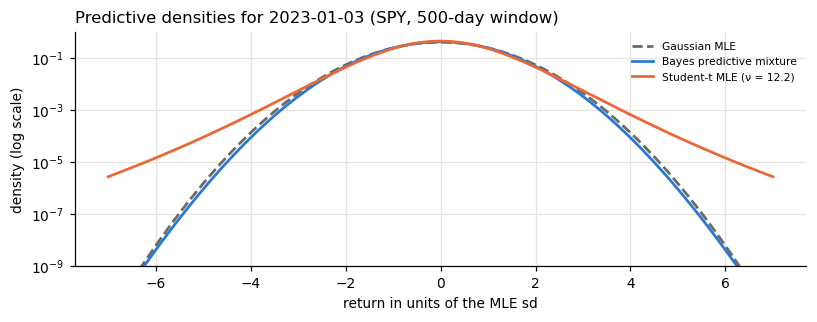

P(return < -4 MLE sd): {'Gaussian MLE': '3.1e-05', 'Bayes predictive mixture': '1.9e-05', 'Student-t MLE (ν = 12.2)': '3.2e-04'} | mixture excess kurtosis 3CV² = 0.020


In [9]:
u_t, nu_hat, fit_t = tg.t_mle_fit(train, u_hat)
check('fresh Student-t nu == saved research fit', np.isclose(nu_hat, f_spy.t_nu.iloc[0], rtol=1e-6), f'nu = {nu_hat:.2f}', RAW)
h_t = garch.variance_path(local, W, u_t)
check('fresh Student-t next-day variance == saved forecast', np.isclose(h_t[0], f_spy.variance_t.iloc[0], rtol=1e-6), level=RAW)
sd = np.sqrt(h_mle[0]); xs = np.linspace(-7, 7, 600) * sd
dens = {'Gaussian MLE': (norm.pdf(xs, scale=sd), GREY, '--'),
        'Bayes predictive mixture': (np.exp(fc.mixture_logpdf(xs, v0[:, None] * np.ones((1, len(xs))))), C[0], '-'),
        f'Student-t MLE (ν = {nu_hat:.1f})': (np.exp(tg.t_logpdf(xs, np.full(len(xs), h_t[0]), nu_hat)), C[1], '-')}
fig, ax = plt.subplots(figsize=(7.5, 3))
for k, (d, c, ls) in dens.items(): ax.semilogy(xs / sd, d * sd, color=c, ls=ls, lw=1.8, label=k)
ax.set_ylim(1e-9, 1); ax.set_xlabel('return in units of the MLE sd'); ax.set_ylabel('density (log scale)'); ax.legend(fontsize=7)
ax.set_title('Predictive densities for 2023-01-03 (SPY, 500-day window)', loc='left'); plt.tight_layout(); plt.show()
tail = {k: float(np.trapz(d[xs < -4 * sd], xs[xs < -4 * sd])) for k, (d, _, _) in dens.items()}
print('P(return < -4 MLE sd):', {k: f'{v:.1e}' for k, v in tail.items()}, f'| mixture excess kurtosis 3CV² = {3*cv**2:.3f}')

**Interpretation.** On this day the Bayesian mixture is almost indistinguishable from the MLE Gaussian, because the
posterior spread of the forecast is small (implied excess kurtosis about 0.02). It even puts slightly *less* mass below
$-4$ MLE standard deviations than the MLE Gaussian, because its average variance is a little lower. The Student-$t$
density ($\hat\nu\approx12$ on this calm window) puts about ten times more probability there. Which mechanism matters
for forecasting real returns is the H2 question.

## 6. Data and rolling experimental design

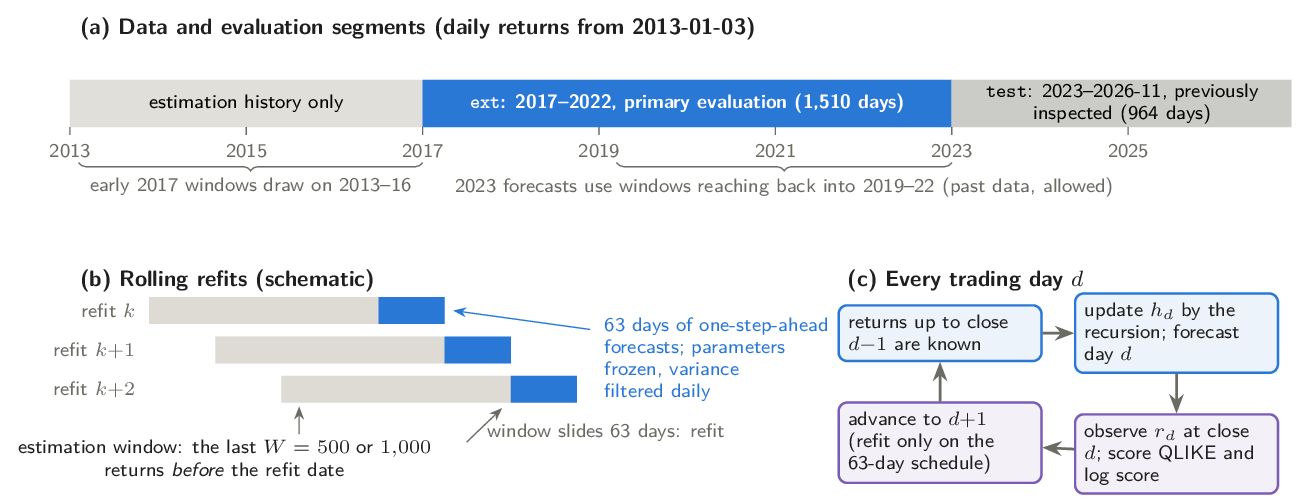

Five things must be kept apart:
1. **Complete return history** (from 2013), from which windows are drawn.
2. **Moving estimation window:** the last $W\in\{500,1000\}$ returns *before* a refit date.
3. **Evaluation dates:** every trading day of the evaluation period gets a one-step-ahead forecast.
4. **Refitting schedule:** parameters (MLE, posterior draws, Laplace, Student-$t$) are re-estimated every **63 trading
   days** and then frozen.
5. **Daily variance updates:** between refits each recursion is updated daily with the newly observed return.

This gives 2 periods × 4 ETFs × 2 windows = 16 jobs and **320 refits**.

**Evaluation segments.** `ext` = 2017–2022 (1,510 days per ETF) is the **primary evaluation**: it is independent of
earlier *inspection*, because the methods were frozen before it was examined (its returns are, of course, not
statistically independent of other years). `test` = 2023–2026 (964 days) had been inspected in earlier milestones and is
reported as a reproduction. Both are chronological out-of-sample forecasts; neither is a training set. Earlier returns
legitimately enter later windows (e.g. 2023 windows reach back into 2019–22).

**Benchmarks.** *EWMA* $h_t=0.94\,h_{t-1}+0.06\,r_{t-1}^2$ needs no estimation. The *Laplace* approximation draws
$u\sim N(\hat u,\hat{\mathcal I}^{-1})$ from the curvature at the MLE: a *classical* version of parameter uncertainty.

**Computational strategy.** The 320 refits take about a minute on 7 cores and are not rerun here. The checksum-verified
daily forecasts and posterior draws are loaded (🔵) and every metric is recomputed from them. Full rebuild:
`python -m bgarch_experiments.reproduce full --out NEW_DIR` (README). The cell below checks the saved structure and runs
a look-ahead canary (🟢).

In [10]:
struct = pd.DataFrame([N.artifact_structure(STORE, a, w, s_, draws_dir=cfg.SAVED_FORECASTS) for s_ in SEGS for a in ASSETS for w in WINDOWS])
check('16 saved jobs: calendar, 63-day refits, fit windows ending before forecasts, shapes', bool(struct.select_dtypes(bool).all().all()) and struct.refits.sum() == 320,
      f'{struct.refits.sum()} refits, {struct.rows.sum():,} forecast rows', FC)
blk = local.copy(); base = garch.variance_path(blk, W, u_hat); blk[W + 30] *= 25          # huge shock on forecast day 30
changed = np.flatnonzero(garch.variance_path(blk, W, u_hat) != base)
check('look-ahead canary: shocking r_d changes forecasts only from day d+1 on', changed.min() == 31, f'first changed row {changed.min()}', RAW)

PASS  16 saved jobs: calendar, 63-day refits, fit windows ending before forecasts, shapes  [320 refits, 19,792 forecast rows]
PASS  look-ahead canary: shocking r_d changes forecasts only from day d+1 on  [first changed row 31]


## 7. H1 — Conditional variance forecasting

**Question.** Does the posterior-integrated forecast $\bar h_t=E_{\theta\mid D_{t-1}}[h_t(\theta)]$ beat the MLE forecast
$h_t(\hat\theta)$?

**The problem.** The true variance is never observed. The squared return is an *unbiased* proxy,
$E[r_t^2\mid\mathcal F_{t-1}]=h_t$, but a very noisy one.

**Metric: QLIKE** (lower is better)
$$\text{QLIKE}_t(\hat h)=\log\hat h_t+\frac{r_t^2}{\hat h_t}.$$

**Why it is appropriate.** With $h^\*=E[r_t^2\mid\mathcal F_{t-1}]$,
$E[\text{QLIKE}_t(\hat h)\mid\mathcal F_{t-1}]=\log\hat h+h^\*/\hat h$, minimised only at $\hat h=h^\*$. The expected excess
loss is $x-1-\log x\ge0$ with $x=h^\*/\hat h$. So the ranking by *expected* QLIKE is the same as against the true variance, **despite the noisy proxy**;
in a finite sample the proxy noise remains, which is why average differences are tested below. The argument needs only
a finite conditional second moment, $E[r_t^2\mid\mathcal F_{t-1}]=h^\*$, **not Gaussian returns**. For a Gaussian forecast, QLIKE is
twice the negative log-likelihood minus a constant: $-\log N(r;0,\hat h)=\tfrac12(\log2\pi+\text{QLIKE})$.

**Numerical check (🟢).** Simulated heavy-tailed returns ($t_5$ innovations) with known variance: average QLIKE is
smallest when the forecast equals the truth.

PASS  QLIKE is minimised by the true variance even with t5 returns  [argmin at 1.00 x truth]


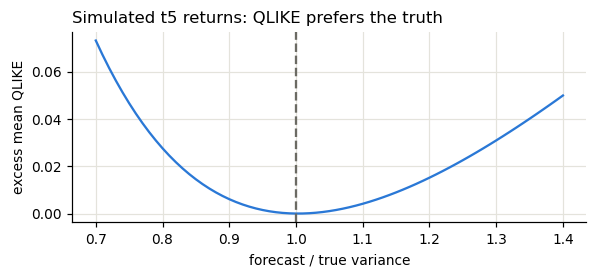

In [11]:
rng_q = np.random.default_rng(7); h_true = 1e-4 * np.exp(rng_q.normal(0, .5, 400_000))
r_sim = np.sqrt(h_true) * rng_q.standard_t(5, h_true.size) / np.sqrt(5 / 3)          # unit-variance t5 innovations
scale = np.linspace(.7, 1.4, 71); q_avg = [ev.qlike(r_sim ** 2, c * h_true).mean() for c in scale]
c_best = scale[int(np.argmin(q_avg))]
check('QLIKE is minimised by the true variance even with t5 returns', abs(c_best - 1) <= .03, f'argmin at {c_best:.2f} x truth', RAW)
fig, ax = plt.subplots(figsize=(5.5, 2.6)); ax.plot(scale, np.array(q_avg) - min(q_avg), color=C[0])
ax.axvline(1, color=GREY, ls='--'); ax.set_xlabel('forecast / true variance'); ax.set_ylabel('excess mean QLIKE')
ax.set_title('Simulated t5 returns: QLIKE prefers the truth', loc='left'); plt.tight_layout(); plt.show()

**Testing.** For forecasts A and B, form the daily differential $d_t=L^A_t-L^B_t$, average it across the four ETFs by
day, and test $E[d_t]=0$ with the Diebold–Mariano statistic $\bar d/\widehat{\mathrm{se}}_{\mathrm{NW}}$; the Newey–West
standard error allows for autocorrelation and heteroskedasticity. A non-significant difference is not proof of equality.

**Recomputation (🔵).** All contrasts for H1 *and* H2 are recomputed here from the saved daily forecasts: QLIKE from the
saved variances; Gaussian log scores from the variances; the Bayesian mixture score from the 300 saved posterior variance
draws per day; the Student-$t$ score from the saved variances and $\hat\nu$; the Laplace mixture score from its saved
daily column (Laplace draws were not stored). The H1 rows are shown now, the H2 rows in §8.

In [12]:
t0 = time.perf_counter(); daily = {}
for s_ in SEGS:
    for a in ASSETS:
        for w in WINDOWS:
            f = STORE.daily(a, w, s_); y = f.return_log.to_numpy(); y2 = y ** 2
            v = np.load(cfg.SAVED_FORECASTS / f'{STORE.name(a, w, s_)}_draws.npz')['v'].astype(float)   # (300, days)
            ls_mix = fc.mixture_logpdf(y, v)
            daily[(s_, a, w)] = pd.DataFrame({
                'qlike_integrated_minus_mle': ev.qlike(y2, f.variance_bayes_integrated.to_numpy()) - ev.qlike(y2, f.variance_mle.to_numpy()),
                'qlike_meanplug_minus_mle': ev.qlike(y2, f.variance_bayes_meanplug.to_numpy()) - ev.qlike(y2, f.variance_mle.to_numpy()),
                'ls_mixture_minus_mle': ls_mix - fc.gaussian_logpdf(y, f.variance_mle.to_numpy()),
                'ls_t_minus_mle': tg.t_logpdf(y, f.variance_t.to_numpy(), f.t_nu.to_numpy()) - fc.gaussian_logpdf(y, f.variance_mle.to_numpy()),
                'ls_laplace_minus_mle': f.logscore_laplace_mixture.to_numpy() - fc.gaussian_logpdf(y, f.variance_mle.to_numpy())},
                index=f.date)
rows = []
for s_ in SEGS:
    ref = pd.read_csv(cfg.SAVED_PRIMARY / f'forecast_pooled_{s_}.csv').set_index(['contrast', 'window'])
    for w in WINDOWS:
        for k in daily[(s_, 'SPY', w)].columns:
            d = pd.concat([daily[(s_, a, w)][k] for a in ASSETS], axis=1).dropna().mean(axis=1).to_numpy()   # pool the 4 ETFs by day
            m_, se, z_, p_ = ev.hac_mean(d)
            rows.append(dict(period=SEGL[s_], window=w, contrast=k, mean=m_, ci_lo=m_ - 1.96 * se, ci_hi=m_ + 1.96 * se, p=p_,
                             research_mean=ref.loc[(k, w), 'pooled_mean']))
P = pd.DataFrame(rows)
check('pooled contrasts recomputed from daily data == report Tables 2-3 (|diff| < 1e-7; float32 draws)',
      np.allclose(P['mean'], P.research_mean, atol=1e-7, rtol=0), f'max |diff| {np.abs(P["mean"] - P.research_mean).max():.1e}', FC)
print(f'recomputed 16 jobs × 5 contrasts in {time.perf_counter()-t0:.1f} s')
show = lambda pre, cap: display(P[P.contrast.str.startswith(pre)].assign(mean=lambda x: x['mean'] * 1e3)
                                .pivot_table(index='contrast', columns=['period', 'window'], values=['mean', 'p']).round(3).style.set_caption(cap))
show('qlike', 'H1: pooled QLIKE difference × 10⁻³ (negative = first method better) and Newey–West p-value')

PASS  pooled contrasts recomputed from daily data == report Tables 2-3 (|diff| < 1e-7; float32 draws)  [max |diff| 2.5e-11]
recomputed 16 jobs × 5 contrasts in 0.3 s


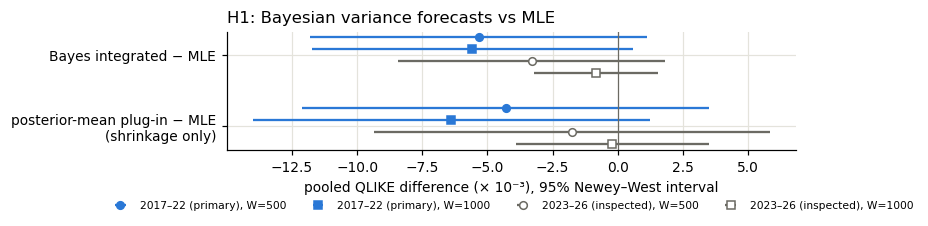

PASS  H1: no Bayesian QLIKE contrast significant at 5% in any cell  [min p 0.076]
PASS  H1: 2017-22 integrated - MLE = -0.005 / -0.006 (p = 0.10 / 0.08)


In [13]:
q1 = P[P.contrast.str.startswith('qlike')]
lab_q = {'qlike_integrated_minus_mle': 'Bayes integrated − MLE', 'qlike_meanplug_minus_mle': 'posterior-mean plug-in − MLE\n(shrinkage only)'}
fig, ax = plt.subplots(figsize=(8, 2.4))
for j, (s_, w) in enumerate([(s_, w) for s_ in SEGS for w in WINDOWS]):
    sub = q1[(q1.period == SEGL[s_]) & (q1.window == w)].set_index('contrast').loc[list(lab_q)]
    y_ = np.arange(len(lab_q)) + (j - 1.5) * .17; col = C[0] if s_ == 'ext' else GREY
    ax.errorbar(sub['mean'] * 1e3, y_, xerr=[(sub['mean'] - sub.ci_lo) * 1e3, (sub.ci_hi - sub['mean']) * 1e3], fmt='os'[j % 2], ms=5,
                color=col, mfc=col if s_ == 'ext' else 'white', label=f'{SEGL[s_]}, W={w}')
ax.axvline(0, color=GREY, lw=.8); ax.set_yticks(range(len(lab_q))); ax.set_yticklabels(lab_q.values()); ax.invert_yaxis()
ax.set_xlabel('pooled QLIKE difference (× 10⁻³), 95% Newey–West interval'); ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.35), ncol=4)
ax.set_title('H1: Bayesian variance forecasts vs MLE', loc='left'); plt.tight_layout(); plt.show()
check('H1: no Bayesian QLIKE contrast significant at 5% in any cell', (q1.p > .05).all(), f'min p {q1.p.min():.3f}', FC)
e1 = q1[(q1.contrast == 'qlike_integrated_minus_mle') & (q1.period == SEGL['ext'])]
check('H1: 2017-22 integrated - MLE = -0.005 / -0.006 (p = 0.10 / 0.08)', list(e1['mean'].round(3)) == [-0.005, -0.006] and list(e1.p.round(2)) == [0.10, 0.08], level=FC)

**Results and conclusion for H1.** In 2017–22 the integrated forecast lowers QLIKE by about 0.005–0.006 (QLIKE levels
are about $-8.3$), with $p=0.10$ and $0.08$; in 2023–26 the differences are smaller. Most of the small effect comes from
prior *shrinkage*, not integration. **H1 is not supported:** the improvements are small and not statistically reliable
at 5%, which is not proof that the forecasts are equal.

*Transition.* A variance is one number. H2 asks whether the *whole* predictive distribution improves.

## 8. H2 — Predictive return distributions

**Question.** Does integrating over parameter uncertainty improve the prediction of the full distribution of daily
returns? QLIKE cannot answer this: two models with similar variances can give very different probabilities to extreme
returns (§5).

**Metric: log predictive score** (higher is better)
$$S_t=\log p\big(r_t^{\text{obs}}\mid D_{t-1}\big).$$
The density is stated before $r_t$ is observed and evaluated at the realised value. The score is strictly proper: in
expectation it is maximised only by the true predictive distribution. For one Gaussian, $-S_t=\tfrac12(\log2\pi+\text{QLIKE}_t)$,
so it ranks Gaussian plug-ins exactly like QLIKE; for mixtures and Student-$t$ densities it also rewards the **shape**.

**Average densities, not log densities.** The Bayesian score is the log of the *mixture*,
$\log\frac1M\sum_m N(r;0,h^{(m)})$, computed by log-sum-exp. By Jensen's inequality it is at least the average of the component log densities on every day; that average is not itself the score of any density (the geometric mean of the components integrates to less than one). The check below confirms both facts on saved draws (🔵).

In [14]:
fx = STORE.daily('SPY', 500, 'ext'); vx = np.load(cfg.SAVED_FORECASTS / f"{STORE.name('SPY', 500, 'ext')}_draws.npz")['v'].astype(float)
yx = fx.return_log.to_numpy(); comp = -.5 * (np.log(2 * np.pi * vx) + yx[None, :] ** 2 / vx)       # (300, days) component log densities
log_mean = np.log(np.exp(comp).mean(0)); mean_log = comp.mean(0)
check('mixture_logpdf == log of the average density (log-sum-exp)', np.allclose(fc.mixture_logpdf(yx, vx), log_mean, atol=1e-10), level=FC)
check('Jensen: log-mean density >= mean log density on every day', (log_mean >= mean_log - 1e-12).all(),
      f'mean gap {np.mean(log_mean - mean_log):.2e} nats/day', FC)
check('saved logscore_bayes_mixture column == recomputed mixture score', np.allclose(fx.logscore_bayes_mixture, log_mean, atol=1e-6), level=FC)

PASS  mixture_logpdf == log of the average density (log-sum-exp)
PASS  Jensen: log-mean density >= mean log density on every day  [mean gap 5.87e-03 nats/day]
PASS  saved logscore_bayes_mixture column == recomputed mixture score


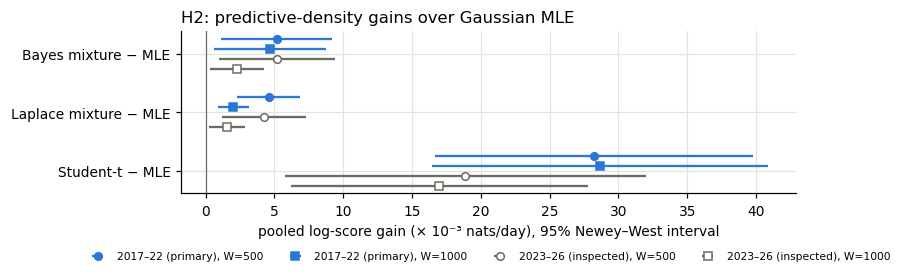

Bayes gain (×10⁻³)  Student-t gain (×10⁻³)  Student-t / Bayes  Laplace share of Bayes gain
period              window                                                                                            
2017–22 (primary)   500                   5.18                   28.22               5.44                         0.89
                    1000                  4.69                   28.65               6.11                         0.43
2023–26 (inspected) 500                   5.19                   18.87               3.64                         0.82
                    1000                  2.26                   16.99               7.52                         0.69

PASS  H2: Bayes mixture beats MLE in every cell, p <= 0.024  [max p 0.024]
PASS  Student-t gain about 5-6x the Bayesian gain in 2017-22; 3.6-7.5x across all cells
PASS  Laplace captures 43-89% of the Bayesian gain
PASS  Student-t beats the Bayes mixture directly in every cell (p <= 0.011)  [max p 0.0108]


In [15]:
show('ls', 'H2: pooled log-score difference × 10⁻³ (positive = first method better) and Newey–West p-value')
labs = {'ls_mixture_minus_mle': 'Bayes mixture − MLE', 'ls_laplace_minus_mle': 'Laplace mixture − MLE', 'ls_t_minus_mle': 'Student-t − MLE'}
fig, ax = plt.subplots(figsize=(8, 2.8))
for j, (s_, w) in enumerate([(s_, w) for s_ in SEGS for w in WINDOWS]):
    sub = P[(P.period == SEGL[s_]) & (P.window == w)].set_index('contrast').loc[list(labs)]
    y_ = np.arange(len(labs)) + (j - 1.5) * .17; col = C[0] if s_ == 'ext' else GREY
    ax.errorbar(sub['mean'] * 1e3, y_, xerr=[(sub['mean'] - sub.ci_lo) * 1e3, (sub.ci_hi - sub['mean']) * 1e3], fmt='os'[j % 2], ms=5,
                color=col, mfc=col if s_ == 'ext' else 'white', label=f'{SEGL[s_]}, W={w}')
ax.axvline(0, color=GREY, lw=.8); ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs.values()); ax.invert_yaxis()
ax.set_xlabel('pooled log-score gain (× 10⁻³ nats/day), 95% Newey–West interval'); ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.3), ncol=4)
ax.set_title('H2: predictive-density gains over Gaussian MLE', loc='left'); plt.tight_layout(); plt.show()
g = P.pivot_table(index=['period', 'window'], columns='contrast', values='mean')
R = pd.DataFrame({'Bayes gain (×10⁻³)': 1e3 * g.ls_mixture_minus_mle, 'Student-t gain (×10⁻³)': 1e3 * g.ls_t_minus_mle,
                  'Student-t / Bayes': g.ls_t_minus_mle / g.ls_mixture_minus_mle, 'Laplace share of Bayes gain': g.ls_laplace_minus_mle / g.ls_mixture_minus_mle})
display(R.round(2))
l1 = P[P.contrast == 'ls_mixture_minus_mle']
check('H2: Bayes mixture beats MLE in every cell, p <= 0.024', (l1['mean'] > 0).all() and l1.p.max() <= .0245, f'max p {l1.p.max():.3f}', FC)
r_ext = R.loc[SEGL['ext'], 'Student-t / Bayes']
check('Student-t gain about 5-6x the Bayesian gain in 2017-22; 3.6-7.5x across all cells',
      r_ext.between(5, 6.5).all() and (round(R['Student-t / Bayes'].min(), 1), round(R['Student-t / Bayes'].max(), 1)) == (3.6, 7.5), level=FC)
check('Laplace captures 43-89% of the Bayesian gain', (round(100 * R.iloc[:, 3].min()), round(100 * R.iloc[:, 3].max())) == (43, 89), level=FC)
tm = pd.concat([pd.read_csv(cfg.SAVED_PRIMARY / f'forecast_pooled_{s_}.csv').assign(seg=s_) for s_ in SEGS]).query("contrast == 'ls_t_minus_mixture'")
check('Student-t beats the Bayes mixture directly in every cell (p <= 0.011)', (tm.pooled_mean > 0).all() and tm.p.max() <= .011, f'max p {tm.p.max():.4f}', ART)

**Results.** The Bayesian mixture beats the MLE density in every cell, by 0.002–0.005 nats/day: statistically reliable
but small ($e^{0.005}-1\approx0.5\%$ more density at the realised return). A classical Laplace approximation recovers
43–89% of it. **Student-$t$ GARCH gains about 0.028 nats/day in 2017–22, 5–6 times the Bayesian gain** (3.6–7.5×
across all cells; the ratio is not constant), and beats the Bayesian mixture directly in every cell.

### Why does Student-$t$ GARCH perform so much better?

1. Gaussian GARCH already models time-varying variance, which makes *unconditional* returns heavy-tailed; the question
   is whether the *conditional* tails are right.
2. Bayesian integration adds one more Gaussian **scale mixture**. If $r=\sqrt H z$ with $z\sim N(0,1)$ independent of $H$,
   then $E r^2=E H$ and $E r^4=3E H^2$, so its excess kurtosis is
   $$\kappa_{\text{excess}}=3\,\frac{\operatorname{Var}(H)}{E[H]^2}=3\,\mathrm{CV}^2.$$
3. That extra tail mass depends on the posterior dispersion of the forecast, which is small here.
4. Student-$t$ innovations put the heavy tails directly into the conditional model.

The cell below measures both sides from the saved forecasts (🔵) and then looks at model adequacy in the 2020 crash.

In [16]:
info_rows = []
for s_ in SEGS:
    for a in ASSETS:
        for w in WINDOWS:
            f_ = STORE.daily(a, w, s_); m_ = f_.variance_bayes_integrated.to_numpy(); cv_ = f_.variance_bayes_sd.to_numpy() / m_
            info_rows.append(dict(period=SEGL[s_], asset=a, window=w, posterior_CV=cv_.mean(), implied_excess_kurtosis=3 * np.mean(cv_ ** 2),
                                  observed_excess_kurtosis=pd.Series(f_.return_log.to_numpy() / np.sqrt(m_)).kurt()))
I = pd.DataFrame(info_rows)
ref_i = pd.concat([pd.read_csv(cfg.SAVED_PRIMARY / f'info_{s_}.csv') for s_ in SEGS])
check('implied (3 CV²) and observed excess kurtosis == research information table', np.allclose(I.implied_excess_kurtosis, ref_i.implied_mixture_excess_kurtosis)
      and np.allclose(I.observed_excess_kurtosis, ref_i.empirical_excess_kurtosis_std_returns), level=FC)
check('posterior CV 7-12% -> implied 0.015-0.046, observed 0.4-2.9', [round(100 * I.posterior_CV.min()), round(100 * I.posterior_CV.max())] == [7, 12]
      and [round(I.implied_excess_kurtosis.min(), 3), round(I.implied_excess_kurtosis.max(), 3)] == [0.015, 0.046]
      and [round(I.observed_excess_kurtosis.min(), 1), round(I.observed_excess_kurtosis.max(), 1)] == [0.4, 2.9], level=FC)
display(I[I.window == 500].set_index(['period', 'asset']).drop(columns='window').round(3)
        .style.set_caption('500-day window: tail heaviness implied by parameter uncertainty vs observed in standardised returns'))

PASS  implied (3 CV²) and observed excess kurtosis == research information table
PASS  posterior CV 7-12% -> implied 0.015-0.046, observed 0.4-2.9


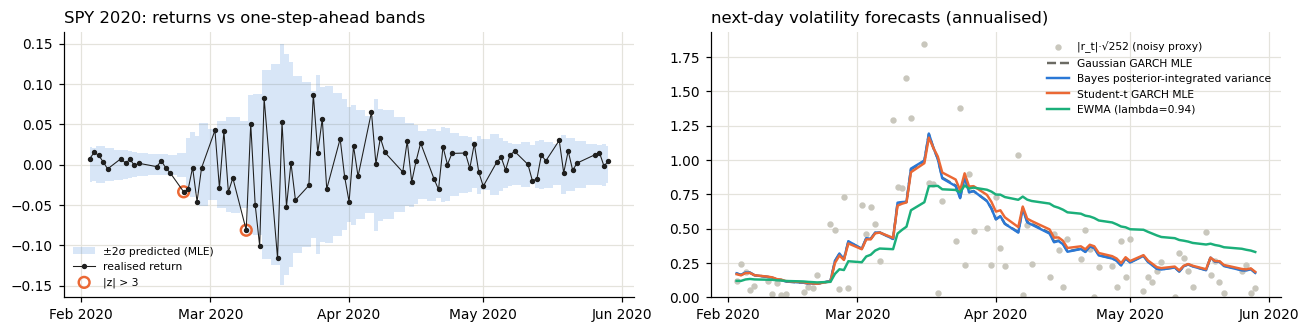

In [17]:
fa, _ = A.load_panel('SPY', 500, ('ext',)); m = ((fa.date >= '2020-02-03') & (fa.date <= '2020-05-29')).to_numpy()
d_ = fa.date[m]; rr = fa.return_log.to_numpy()[m]; sd_ = np.sqrt(fa.variance_mle.to_numpy()[m])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.1))
ax[0].fill_between(d_, -2 * sd_, 2 * sd_, step='mid', color=C[0], alpha=.18, lw=0, label='±2σ predicted (MLE)')
ax[0].plot(d_, rr, 'o-', ms=2.5, lw=.7, color=INK, label='realised return'); big = np.abs(rr / sd_) > 3
ax[0].scatter(d_[big], rr[big], s=50, facecolor='none', edgecolor=C[1], lw=1.6, label='|z| > 3'); ax[0].legend(fontsize=7, loc='lower left')
ax[0].set_title('SPY 2020: returns vs one-step-ahead bands', loc='left')
ax[1].scatter(d_, np.abs(rr) * np.sqrt(252), s=10, color='#c9c7bd', label='|r_t|·√252 (noisy proxy)')
for mod, c, ls in [('mle', GREY, '--'), ('bayes_integrated', C[0], '-'), ('t', C[1], '-'), ('ewma', C[2], '-')]:
    ax[1].plot(d_, A.ann_vol(fa, mod)[m], color=c, ls=ls, lw=1.6, label=A.LABEL[mod])
ax[1].set_ylim(0, None); ax[1].legend(fontsize=7); ax[1].set_title('next-day volatility forecasts (annualised)', loc='left')
import matplotlib.dates as mdates
for a_ in ax: a_.xaxis.set_major_locator(mdates.MonthLocator()); a_.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout(); plt.show()
dt = A.diagnostics_table(500, 'ext').set_index(['asset', 'model'])
display(dt.loc[[('SPY', 'raw returns (no model)'), ('SPY', 'mle'), ('SPY', 'bayes_mixture'), ('SPY', 't')],
               ['acf1_z2', 'skew_z', 'exkurt_normal_scores', 'lower01', 'upper01']].round(3)
        .style.set_caption('SPY 2017–22 out-of-sample diagnostics: lag-1 ACF of z², skew, excess kurtosis of normal scores, 1% tail exceedances'))

**Interpretation.** Parameter uncertainty implies an excess kurtosis of 0.015–0.046; returns standardised by the
Bayesian forecast show 0.4–2.9, so the posterior mixture can explain only a few per cent of the observed tail
heaviness. In the 2020 crash, every GARCH variant reacts within a day (volatility clustering is captured) but many days
fall beyond $\pm3\sigma$, and the lower 1% tail is exceeded far too often. The Bayesian mixture barely changes these
diagnostics; Student-$t$ fixes much of the tail calibration, though not the negative skew of equity returns.

> **Finding 1.** In these experiments, improving the innovation distribution produced a substantially larger
> predictive-density improvement than Bayesian integration of parameter uncertainty under Gaussian GARCH:
> innovation-distribution misspecification is more consequential than parameter uncertainty within the tested model.

This does **not** show that parameter uncertainty is unimportant in general, or that a Bayesian Student-$t$ GARCH would
fail to improve on its MLE version (it was not tested). **H2 is supported, with a small effect.**

*Transition.* Do any of these forecasts make better *portfolios*?

## 9. H3 — From forecasts to portfolios

**Question.** Do improvements in volatility forecasting and uncertainty quantification translate into better
investment decisions?

**Allocation rule.** Hold a fraction $w_d$ of wealth in one ETF and $1-w_d$ in cash, targeting 10% annual volatility,
without leverage:
$$w_d=\min\Big(1,\ \frac{k\cdot0.10}{\sqrt{252\,h_d}}\Big)\in[0,1],\qquad k=1\text{ except for a control introduced in §10.}$$
A higher variance forecast means a smaller ETF weight. The strategies differ only in $h_d$:

| Strategy | Variance $h_d$ |
|---|---|
| MLE | $\hat h_d$ |
| Bayes integrated | $\bar h_d$ |
| Bayes upper-90 | $q_{0.9,d}$: cautious; the 90th percentile is an experimental choice, not an optimum |

**How the backtest runs.** The formula gives the *target*; the flowchart shows how it is executed and how the
portfolio evolves, day after day. It is drawn from the implementation (`portfolio.portfolio` →
`simulate_portfolio`, unchanged from the original project).

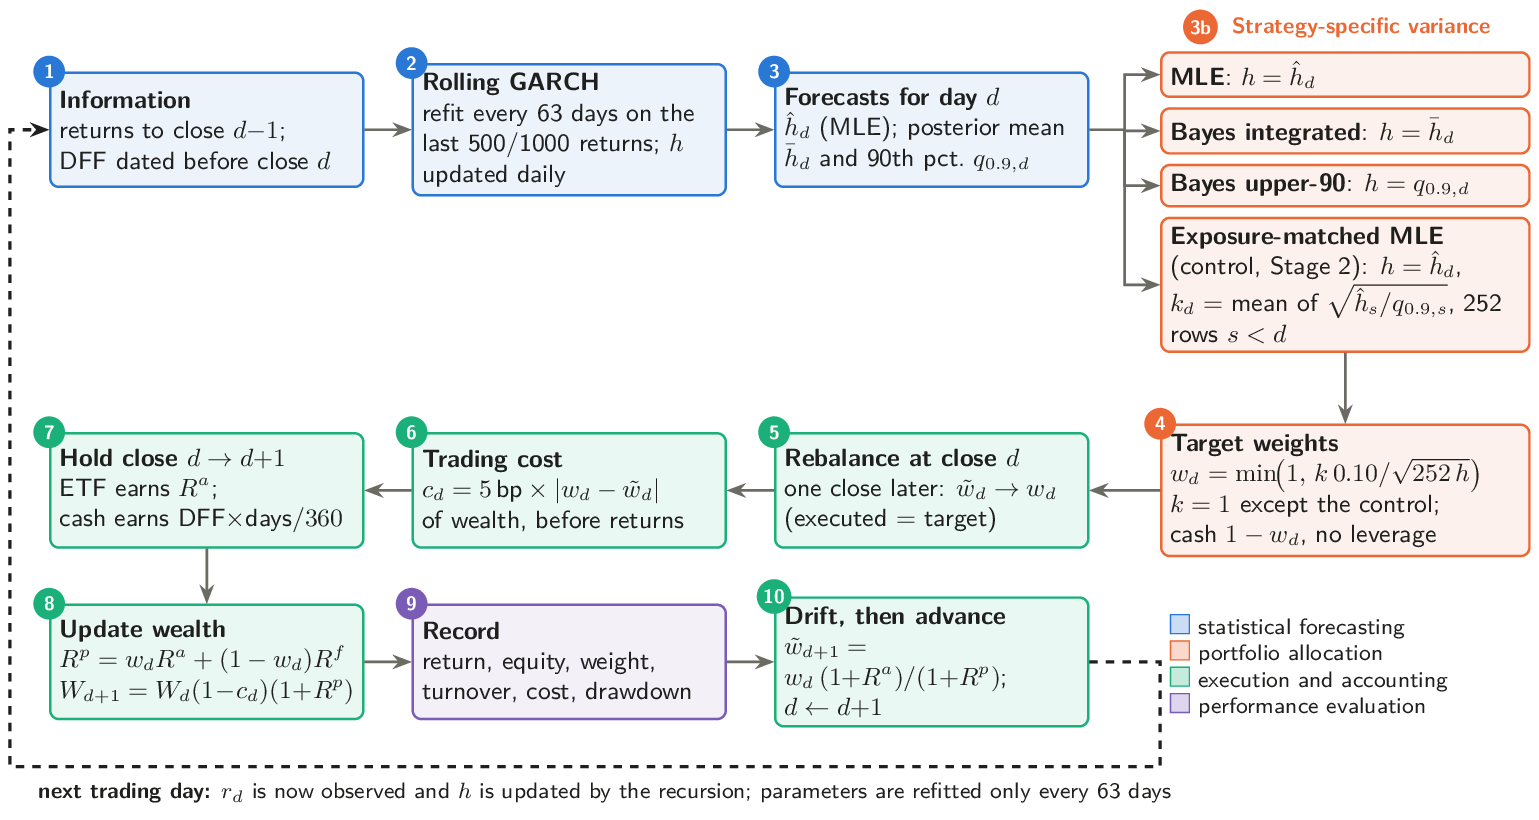

- **Timing.** Forecast row $d$ uses returns to close $d-1$; the trade is executed at **close $d$** (one close later)
  and earns close $d\to d+1$. No forecast uses an unobserved return.
- **Three weights.** *Target* $w_d$ from the rule; *executed* weight $=w_d$ (full daily rebalance; costs reduce wealth,
  not the weight); *post-return* weight $\tilde w_{d+1}=w_d(1+R^a)/(1+R^p)$, the drifted weight before the next trade.
- **Costs** $c_d=5\,\text{bp}\times|w_d-\tilde w_d|$ of wealth, charged before returns and separate from market returns.
- **Cash** earns the DFF rate dated strictly before close $d$, accrued ACT/360 (weekends included).
- **Wealth** $W_{d+1}=W_d(1-c_d)(1+R^p_{d+1})$, $R^p=w_dR^a+(1-w_d)R^f$; it starts at 1, all in cash.

**Worked calculation (🔵 forecasts + 🟢 prices and DFF).** SPY, 500-day window, Bayes upper-90, the first days of
March 2020, step by step, then the explicit ledger for the whole period compared with the simulator.

In [18]:
rates = data.load_rates()
f = STORE.daily('SPY', 500, 'ext'); Wts = strategies.strategy_weights(f, 'SPY', 'ext')
w_tgt = Wts['bayes_upper90']                                     # target weight decided from forecast row d
R_etf = np.expm1(f.return_log.to_numpy()[1:])                    # ... earns the simple return of row d+1
R_cash = pf.cash_returns_for_periods(f.date, rates); wt = w_tgt[:-1]
nav, prev, ledger = 1.0, 0.0, []
for t in range(len(R_etf)):
    turn = abs(wt[t] - prev); cost = turn * 5e-4                 # trade from the drifted weight to the target
    gross = wt[t] * R_etf[t] + (1 - wt[t]) * R_cash[t]; nav_new = nav * (1 - cost) * (1 + gross)
    post = wt[t] * (1 + R_etf[t]) / (1 + gross)                  # drift: weight after one day of returns
    ledger.append(dict(info_to_close=f.date.iloc[t - 1].date() if t else None, trade_close=f.date.iloc[t].date(), earns_to=f.date.iloc[t + 1].date(),
                       forecast_vol=np.sqrt(252 * f.variance_bayes_q90.iloc[t]), target_w=wt[t], cash_w=1 - wt[t], pre_trade_w=prev,
                       turnover=turn, cost_bp_of_wealth=1e4 * cost, etf_ret=R_etf[t], cash_ret=R_cash[t], NAV_before=nav, NAV_after=nav_new, post_return_w=post))
    nav, prev = nav_new, post
ledger = pd.DataFrame(ledger); stats, curve = pf.portfolio(f, w_tgt)
check('explicit ledger == validated simulator, every day', np.allclose(ledger.NAV_after, curve.equity, atol=1e-13, rtol=0), level=FC)
check('simulator equals the research table (SPY, 500d, upper-90)', np.isclose(stats['sharpe_excess_cash'],
      pd.read_csv(cfg.SAVED_PRIMARY / 'alloc_summary_ext.csv').query("asset=='SPY' and window==500 and strategy=='bayes_upper90'").sharpe_excess_cash.iloc[0]), level=FC)
i0 = int(np.flatnonzero(ledger.trade_close.astype(str) == '2020-03-06')[0])
display(ledger.iloc[i0:i0 + 5].set_index('trade_close').T.style.format('{:.5f}', subset=pd.IndexSlice[ledger.columns[3:], :]))
print(f"whole period: Sharpe {stats['sharpe_excess_cash']:.3f}, max drawdown {stats['max_drawdown']:.1%}, mean exposure {stats['mean_exposure']:.3f}, "
      f"mean daily turnover {ledger.turnover.mean():.4f}, total costs {ledger.cost_bp_of_wealth.sum()/1e4:.2%} of wealth")

PASS  explicit ledger == validated simulator, every day
PASS  simulator equals the research table (SPY, 500d, upper-90)


trade_close,2020-03-06,2020-03-09,2020-03-10,2020-03-11,2020-03-12
info_to_close,2020-03-05,2020-03-06,2020-03-09,2020-03-10,2020-03-11
earns_to,2020-03-09,2020-03-10,2020-03-11,2020-03-12,2020-03-13
forecast_vol,0.50081,0.44698,0.74125,0.74186,0.74117
target_w,0.19968,0.22372,0.13491,0.13480,0.13492
cash_w,0.80032,0.77628,0.86509,0.86520,0.86508
pre_trade_w,0.19629,0.18698,0.23260,0.12918,0.12349
turnover,0.00339,0.03674,0.09770,0.00562,0.01143
cost_bp_of_wealth,0.01695,0.18370,0.48848,0.02810,0.05717
etf_ret,-0.07809,0.05175,-0.04875,-0.09568,0.08549
cash_ret,0.00009,0.00003,0.00003,0.00003,0.00003


whole period: Sharpe 0.690, max drawdown -13.6%, mean exposure 0.711, mean daily turnover 0.0481, total costs 3.63% of wealth


**Reading the worked example.** Each column is one trading day. The target weight falls as the forecast volatility
rises into the March 2020 crash; the *pre-trade* weight is yesterday's target after drift, so turnover is the trade
needed to get back to target; the cost is a few basis points of wealth; NAV then moves with the ETF and cash returns,
and the *post-return* weight becomes the next day's pre-trade weight. The hand-written ledger reproduces the simulator
to machine precision.

**Performance metrics.** Sharpe ratio of returns in excess of cash (annualised), maximum drawdown (largest
peak-to-trough NAV loss), annualised return and volatility, mean ETF weight (risky exposure), turnover and costs. Forecast
accuracy alone does not determine these: the weight responds to the *level* of the forecast, and simply holding less
risk changes volatility and drawdown by itself.

## 10. H3 — Portfolio evaluation in two stages

**Metrics.** Average ETF exposure, annualised return, realised volatility, the Sharpe ratio (mean daily return in excess
of cash divided by the standard deviation of that excess return, $\times\sqrt{252}$) and the maximum drawdown. Two
aggregations are kept apart: **means over the 8 single-ETF asset/window configurations** (the stage tables) and the
**equal-weight four-ETF sleeve**. Differences are assessed with a **paired circular block bootstrap** (20-day blocks,
wrap-around, the same days for both strategies, 2,000 replications), which preserves volatility clustering and the
correlation between strategies.

**Recomputation (🔵).** All 16 jobs × 14 strategies are first re-simulated from the saved daily forecasts, prices and
DFF and checked against the research tables; the results are then shown in two stages.

In [19]:
t0 = time.perf_counter(); alloc = {}
for s_ in SEGS:
    alloc[s_] = tables.allocation_tables(s_)                      # (per-job summary, per-job pairs, sleeve summary, sleeve pairs)
    for i, nm in enumerate(['alloc_summary', 'alloc_pairs', 'alloc_pooled_summary', 'alloc_pooled_pairs']):
        ref = pd.read_csv(cfg.SAVED_PRIMARY / f'{nm}_{s_}.csv'); num = ref.select_dtypes('number').columns
        check(f'{nm} {s_} == research table', np.allclose(alloc[s_][i][num].to_numpy(float), ref[num].to_numpy(float), atol=1e-12, rtol=0, equal_nan=True), level=FC)
print(f're-simulated in {time.perf_counter()-t0:.0f} s')
ROWS = [('buy_hold', 'Buy and hold'), ('ewma', 'EWMA'), ('t_garch', 'Student-t GARCH'), ('mle', 'Gaussian GARCH, MLE'),
        ('bayes_integrated', 'Bayes, integrated'), ('bayes_upper90', 'Bayes, upper-90'), ('mle_const_rt', 'MLE × real-time haircut (control)')]
T3 = pd.concat({SEGL[s_]: alloc[s_][2].set_index(['strategy', 'window'])[['sharpe', 'max_dd']].unstack('window') for s_ in SEGS}, axis=1).loc[[k for k, _ in ROWS]]
T3.index = [l for _, l in ROWS]                                   # shown after Stage 2
rows = []
for s_ in SEGS:
    S = alloc[s_][0].pivot_table(index=['asset', 'window'], columns='strategy', values=['mean_exposure', 'max_drawdown', 'sharpe_excess_cash'])
    d_mle = S['max_drawdown']['bayes_upper90'] - S['max_drawdown']['mle']; d_ctl = S['max_drawdown']['bayes_upper90'] - S['max_drawdown']['mle_const_rt']
    rows.append({'period': SEGL[s_], 'Δexposure vs MLE (pp)': 100 * (S['mean_exposure']['bayes_upper90'] - S['mean_exposure']['mle']).mean(),
                 'ΔmaxDD vs MLE (pp)': 100 * d_mle.mean(), 'smaller DD than MLE': f'{int((d_mle > 0).sum())}/8',
                 'ΔmaxDD vs control (pp)': 100 * d_ctl.mean(), 'smaller DD than control': f'{int((d_ctl > 0).sum())}/8',
                 'ΔSharpe vs control': (S['sharpe_excess_cash']['bayes_upper90'] - S['sharpe_excess_cash']['mle_const_rt']).mean()})
T5 = pd.DataFrame(rows).set_index('period')                       # shown after Stage 2

PASS  alloc_summary ext == research table
PASS  alloc_pairs ext == research table
PASS  alloc_pooled_summary ext == research table
PASS  alloc_pooled_pairs ext == research table
PASS  alloc_summary test == research table
PASS  alloc_pairs test == research table
PASS  alloc_pooled_summary test == research table
PASS  alloc_pooled_pairs test == research table
re-simulated in 20 s


### Stage 1 — Bayesian upper-90 versus standard MLE

The two rules of interest, side by side (2017–22). The matched control is deliberately absent: it has not been
introduced yet.

In [20]:
COLS = ['mean_exposure', 'annualized_return', 'realized_annual_volatility', 'sharpe_excess_cash', 'max_drawdown']
def stage_table(b, lab_b, seg='ext'):
    S_ = alloc[seg][0]; g = S_[S_.strategy.isin([b, 'bayes_upper90'])].groupby('strategy')[COLS].mean().loc[[b, 'bayes_upper90']]
    d = g.loc['bayes_upper90'] - g.loc[b]
    x = alloc[seg][1]; x = x[(x.a == 'bayes_upper90') & (x.b == b)]                 # per-configuration paired bootstrap
    excl = lambda lo, hi: int(((x[lo] > 0) | (x[hi] < 0)).sum())
    tab = pd.DataFrame({'ETF exposure (%)': 100 * g.mean_exposure, 'return (%)': 100 * g.annualized_return,
                        'volatility (%)': 100 * g.realized_annual_volatility, 'Sharpe': g.sharpe_excess_cash, 'max drawdown (%)': 100 * g.max_drawdown})
    tab.index = [lab_b, 'Bayesian upper-90']
    tab.loc['difference (upper-90 − ' + lab_b + ')'] = [100 * d.mean_exposure, 100 * d.annualized_return, 100 * d.realized_annual_volatility, d.sharpe_excess_cash, 100 * d.max_drawdown]
    sl = alloc[seg][3].set_index(['a', 'b', 'window'])
    ci = pd.DataFrame({w: sl.loc[('bayes_upper90', b, w), ['d_sharpe', 'd_sharpe_lo', 'd_sharpe_hi', 'd_maxdd', 'd_maxdd_lo', 'd_maxdd_hi']] for w in WINDOWS}).T
    return tab, excl('d_sharpe_lo', 'd_sharpe_hi'), excl('d_maxdd_lo', 'd_maxdd_hi'), ci
tab1, n_sh1, n_dd1, ci1 = stage_table('mle', 'standard MLE')
display(tab1.round(3).style.set_caption('Stage 1, 2017–22: means over the 8 single-ETF configurations'))
print(f'configurations whose 95% CI excludes 0: Sharpe {n_sh1} of 8, max drawdown {n_dd1} of 8')
display(ci1.round(4).style.set_caption('Four-ETF sleeve: upper-90 − MLE, paired block-bootstrap 95% CIs (drawdown: + = shallower)'))
check('Stage 1: exposure 73.1% vs 69.6%, volatility 10.37% vs 9.81%, Sharpe 0.518 vs 0.520, max DD -19.55% vs -18.74%',
      list(tab1.iloc[:2, 0].round(1)) == [73.1, 69.6] and list(tab1.iloc[:2, 2].round(2)) == [10.37, 9.81]
      and list(tab1.iloc[:2, 3].round(3)) == [0.518, 0.520] and list(tab1.iloc[:2, 4].round(2)) == [-19.55, -18.74], level=FC)
check('Stage 1 CIs: drawdown excludes 0 in 8 of 8, Sharpe in 0 of 8', (n_dd1, n_sh1) == (8, 0), level=FC)

,ETF exposure (%),return (%),volatility (%),Sharpe,max drawdown (%)
standard MLE,73.129000,6.250000,10.369000,0.518000,-19.551000
Bayesian upper-90,69.565000,6.055000,9.814000,0.520000,-18.735000
difference (upper-90 − standard MLE),-3.564000,-0.194000,-0.555000,0.002000,0.816000


configurations whose 95% CI excludes 0: Sharpe 0 of 8, max drawdown 8 of 8


,d_sharpe,d_sharpe_lo,d_sharpe_hi,d_maxdd,d_maxdd_lo,d_maxdd_hi
500,0.011000,-0.021000,0.042100,0.007600,0.002200,0.012100
1000,0.000300,-0.025100,0.025900,0.005500,0.001100,0.010100


PASS  Stage 1: exposure 73.1% vs 69.6%, volatility 10.37% vs 9.81%, Sharpe 0.518 vs 0.520, max DD -19.55% vs -18.74%
PASS  Stage 1 CIs: drawdown excludes 0 in 8 of 8, Sharpe in 0 of 8


**Observation.** Upper-90 has lower volatility and a shallower maximum drawdown (by 0.82 points; smaller in 8 of 8
configurations, each interval excluding zero). But it also holds 3.6 points less ETF and earns slightly less, and its
Sharpe ratio is nearly unchanged: no configuration interval excludes zero, and the sleeve intervals straddle zero.

**Interpretation.** Upper-90 takes less risk at almost the same risk-adjusted return, which is the pattern a lower
volatility target would also produce. The table cannot say *why* the drawdown is lower.

> **Question raised by Stage 1.** Does Bayesian uncertainty improve allocation **timing**, or is the lower drawdown
> simply a consequence of **holding less risk**?

### Stage 2 — the exposure-matched MLE control

**Objective.** Hold upper-90's average risk with **no** posterior information. If upper-90 only holds less risk
(explanation A), the two should perform alike; if the posterior tells it *when* to cut risk (explanation B), upper-90
should still win.

**Rule and calibration.** Keep the MLE variance forecast unchanged and scale only the volatility target:
$$w^{\text{ctrl}}_d=\min\Big(1,\ \frac{k_d\,0.10}{\sqrt{252\,\hat h_d}}\Big),\qquad k_d=\frac{1}{d-\max(0,d-252)}\sum_{s=\max(0,d-252)}^{d-1}\sqrt{\hat h_s/q_{0.9,s}},\quad k_0=\sqrt{\hat h_0/q_{0.9,0}}.$$
$k_d$ is upper-90's average *haircut* (the ratio of the uncapped weights) over up to 252 earlier forecast rows: it uses
only past information (no realised return enters it directly), changes only the effective target $0.10\,k_d$ — not
the GARCH parameters or the variance forecast — and keeps universe, timing, costs and cash identical. It matches
*average* exposure approximately (weights are capped at 1), not daily risk.

**Implementation check (🔵).** $k_d$ rebuilt here, a look-ahead canary on it, and the exposure match:

In [21]:
k_d = pf.trailing_mean_known(np.sqrt(f.variance_mle.to_numpy() / f.variance_bayes_q90.to_numpy()), 252)
w_ctrl = np.minimum(1, k_d * 0.10 / np.sqrt(252 * f.variance_mle.to_numpy()))
check('rebuilt control weights == strategy_weights["mle_const_rt"]', np.allclose(w_ctrl, Wts['mle_const_rt'], atol=0, rtol=0), level=FC)
q_pert = f.variance_bayes_q90.to_numpy().copy(); d0 = 700; q_pert[d0:] *= 3                  # change all FUTURE upper-90 forecasts
k_p = pf.trailing_mean_known(np.sqrt(f.variance_mle.to_numpy() / q_pert), 252)
check('canary: k_d uses only rows before d (changing rows >= d leaves k_0..k_d unchanged)', np.array_equal(k_p[:d0 + 1], k_d[:d0 + 1]) and k_p[d0 + 1] != k_d[d0 + 1], level=FC)
expo = pd.concat([pd.read_csv(cfg.SAVED_PRIMARY / f'alloc_summary_{s_}.csv').assign(period=SEGL[s_]) for s_ in SEGS])
E = expo.pivot_table(index=['period', 'asset', 'window'], columns='strategy', values='mean_exposure')
gap = 100 * (E.bayes_upper90 - E.mle_const_rt)
display(pd.DataFrame({'upper-90 − MLE (pp)': 100 * (E.bayes_upper90 - E.mle), 'upper-90 − control (pp)': gap}).groupby('period').agg(['mean', 'min', 'max']).round(2)
        .style.set_caption('Exposure gaps over the 8 ETF × window configurations'))

PASS  rebuilt control weights == strategy_weights["mle_const_rt"]
PASS  canary: k_d uses only rows before d (changing rows >= d leaves k_0..k_d unchanged)


### Stage 2 results — upper-90 versus exposure-matched MLE

The same metrics, now against the control (2017–22), followed by the evidence for both periods and the sleeve.

,ETF exposure (%),return (%),volatility (%),Sharpe,max drawdown (%)
exposure-matched MLE,69.446000,6.013000,9.847000,0.516000,-18.662000
Bayesian upper-90,69.565000,6.055000,9.814000,0.520000,-18.735000
difference (upper-90 − exposure-matched MLE),0.119000,0.042000,-0.032000,0.003000,-0.074000


configurations whose 95% CI excludes 0: Sharpe 0 of 8, max drawdown 0 of 8


,d_sharpe,d_sharpe_lo,d_sharpe_hi,d_maxdd,d_maxdd_lo,d_maxdd_hi
500,0.009400,-0.016400,0.036400,-0.000100,-0.002200,0.004300
1000,0.004600,-0.015500,0.027500,-0.000300,-0.002000,0.004500


PASS  Stage 2: no Sharpe or drawdown CI excludes 0; exposure gap +0.1 pp


,Δexposure vs MLE (pp),ΔmaxDD vs MLE (pp),smaller DD than MLE,ΔmaxDD vs control (pp),smaller DD than control,ΔSharpe vs control
period,,,,,,
2017–22 (primary),-3.564000,0.816000,8/8,-0.074000,2/8,0.003000
2023–26 (inspected),-4.097000,1.024000,8/8,0.090000,4/8,-0.001000


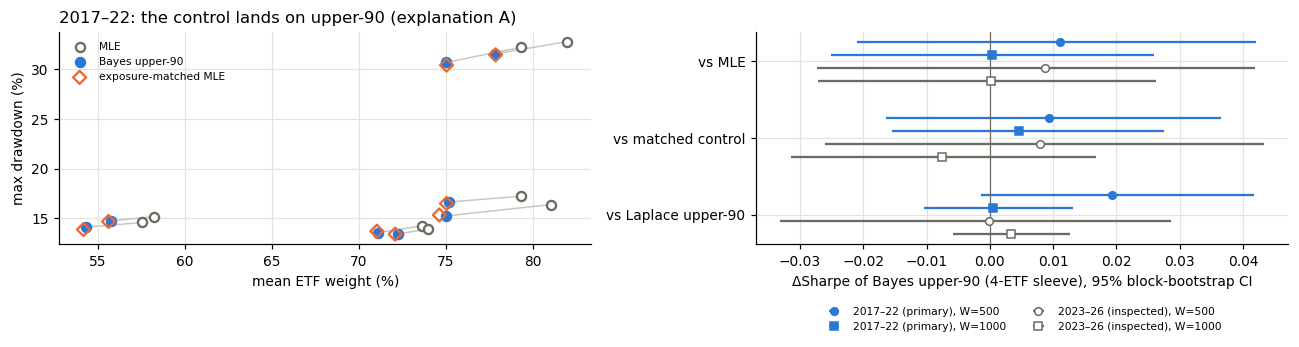

PASS  every 95% CI for upper-90 vs MLE / control / Laplace contains zero  [12 intervals]
PASS  2017-22: smaller drawdown than MLE 8/8, than the control 2/8; exposure -3.6 / +0.1 pp


In [22]:
tab2, n_sh2, n_dd2, ci2 = stage_table('mle_const_rt', 'exposure-matched MLE')
display(tab2.round(3).style.set_caption('Stage 2, 2017–22: means over the 8 single-ETF configurations'))
print(f'configurations whose 95% CI excludes 0: Sharpe {n_sh2} of 8, max drawdown {n_dd2} of 8')
display(ci2.round(4).style.set_caption('Four-ETF sleeve: upper-90 − exposure-matched MLE, paired block-bootstrap 95% CIs'))
check('Stage 2: no Sharpe or drawdown CI excludes 0; exposure gap +0.1 pp', (n_sh2, n_dd2) == (0, 0) and round(gap.loc[SEGL['ext']].mean(), 1) == 0.1, level=FC)
display(T5.round(3).style.set_caption('Both periods: upper-90 minus MLE and minus the control, mean over 8 configurations'))
display(T3.round(3).style.set_caption('Four-ETF sleeve: Sharpe ratio and maximum drawdown, all rules'))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
S5 = alloc['ext'][0].pivot_table(index=['asset', 'window'], columns='strategy', values=['mean_exposure', 'max_drawdown'])
e5, dd5 = 100 * S5['mean_exposure'], -100 * S5['max_drawdown']
for idx in e5.index: ax[0].plot([e5.loc[idx, 'mle'], e5.loc[idx, 'bayes_upper90']], [dd5.loc[idx, 'mle'], dd5.loc[idx, 'bayes_upper90']], color='#c9c7bd', lw=1)
for k, lab, c, mk, fcol in [('mle', 'MLE', GREY, 'o', 'white'), ('bayes_upper90', 'Bayes upper-90', C[0], 'o', C[0]), ('mle_const_rt', 'exposure-matched MLE', C[1], 'D', 'none')]:
    ax[0].scatter(e5[k], dd5[k], s=36, marker=mk, facecolor=fcol, edgecolor=c, lw=1.5, label=lab, zorder=3)
ax[0].set_xlabel('mean ETF weight (%)'); ax[0].set_ylabel('max drawdown (%)'); ax[0].legend(fontsize=7)
ax[0].set_title('2017–22: the control lands on upper-90 (explanation A)', loc='left')
comps = [('mle', 'vs MLE'), ('mle_const_rt', 'vs matched control'), ('laplace_upper90', 'vs Laplace upper-90')]
for j, (s_, w) in enumerate([(s_, w) for s_ in SEGS for w in WINDOWS]):
    PP = alloc[s_][3].set_index(['a', 'b', 'window']); rr_ = [PP.loc[('bayes_upper90', b, w)] for b, _ in comps]
    mu = np.array([q.d_sharpe for q in rr_]); y_ = np.arange(3) + (j - 1.5) * .17; col = C[0] if s_ == 'ext' else GREY
    ax[1].errorbar(mu, y_, xerr=[mu - [q.d_sharpe_lo for q in rr_], [q.d_sharpe_hi for q in rr_] - mu], fmt='os'[j % 2], ms=5, color=col,
                   mfc=col if s_ == 'ext' else 'white', label=f'{SEGL[s_]}, W={w}')
ax[1].axvline(0, color=GREY, lw=.8); ax[1].set_yticks(range(3)); ax[1].set_yticklabels([l for _, l in comps]); ax[1].invert_yaxis()
ax[1].set_xlabel('ΔSharpe of Bayes upper-90 (4-ETF sleeve), 95% block-bootstrap CI'); ax[1].legend(fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.25), ncol=2)
plt.tight_layout(); plt.show()
sel = pd.concat([alloc[s_][3] for s_ in SEGS]); sel = sel[(sel.a == 'bayes_upper90') & sel.b.isin([b for b, _ in comps])]
check('every 95% CI for upper-90 vs MLE / control / Laplace contains zero', ((sel.d_sharpe_lo < 0) & (sel.d_sharpe_hi > 0)).all(), f'{len(sel)} intervals', FC)
check('2017-22: smaller drawdown than MLE 8/8, than the control 2/8; exposure -3.6 / +0.1 pp',
      T5.loc[SEGL['ext'], 'smaller DD than MLE'] == '8/8' and T5.loc[SEGL['ext'], 'smaller DD than control'] == '2/8'
      and round(T5.loc[SEGL['ext'], 'Δexposure vs MLE (pp)'], 1) == -3.6 and round(gap.loc[SEGL['ext']].mean(), 1) == 0.1, level=FC)

**The bootstrap, by hand.** One table entry rebuilt from scratch: the 2017–22 four-ETF sleeve ($W=500$), upper-90 versus the control.

In [23]:
rr = {'bayes_upper90': [], 'mle_const_rt': []}; rf = []
for a in ASSETS:
    fa_ = STORE.daily(a, 500, 'ext'); Wa = strategies.strategy_weights(fa_, a, 'ext')
    for k in rr:
        _, c_ = pf.portfolio(fa_, Wa[k]); rr[k].append(c_.portfolio_return.to_numpy())
    rf.append(c_.risk_free_return.to_numpy())
ra, rb, rfm = np.mean(rr['bayes_upper90'], 0), np.mean(rr['mle_const_rt'], 0), np.mean(rf, 0)        # equal-weight sleeves
bs = ev.paired_bootstrap(ra, rb, rfm, B=2000, block=20, seed=zlib.crc32(b'500bayes_upper90mle_const_rt'))
iid = ev.paired_bootstrap(ra, rb, rfm, B=2000, block=1, seed=1)
row = alloc['ext'][3].set_index(['a', 'b', 'window']).loc[('bayes_upper90', 'mle_const_rt', 500)]
check('hand-built sleeve + block bootstrap == research table entry', np.isclose(bs['d_sharpe_lo'], row.d_sharpe_lo) and np.isclose(bs['d_sharpe_hi'], row.d_sharpe_hi), level=FC)
print(f"ΔSharpe {bs['d_sharpe']:+.4f};  95% CI, 20-day blocks [{bs['d_sharpe_lo']:+.4f}, {bs['d_sharpe_hi']:+.4f}];  "
      f"i.i.d. resampling [{iid['d_sharpe_lo']:+.4f}, {iid['d_sharpe_hi']:+.4f}]")

PASS  hand-built sleeve + block bootstrap == research table entry
ΔSharpe +0.0094;  95% CI, 20-day blocks [-0.0164, +0.0364];  i.i.d. resampling [-0.0234, +0.0436]


**Observation.** Once average exposure is matched ($+0.1$ points), realised volatility, maximum drawdown and the Sharpe
ratio are very similar; upper-90's drawdown is smaller in only 2 of 8 configurations, and no configuration interval
excludes zero for either metric. In the sleeve, the drawdown advantage over MLE has intervals excluding zero, but
against the control it does not, and every Sharpe-difference interval (12, both periods) contains zero. The same holds
in 2023–26 (drawdown smaller than the control in 4 of 8, Sharpe difference $-0.001$).

**Interpretation.** The Stage 1 drawdown gain is reproduced by a strategy that simply holds the same average risk
without any posterior information. Sharpe point estimates are small and of either sign, with intervals a few
hundredths wide, so no statistically reliable incremental benefit is established; rounded point estimates should not be
read as a gain or a loss.

> **Finding 2.** The drawdown reduction is largely consistent with reduced risky exposure rather than demonstrably
> superior risk timing from Bayesian parameter uncertainty. Better-looking portfolio performance must be examined against
> appropriately controlled alternatives.

**H3 is not supported.** This does not rule out every possible benefit of Bayesian inference for allocation, and
matching average exposure is not a perfect control for all differences in risk.

## 11. Limitations and future research

**Limitations of the tested design.** Only symmetric Gaussian GARCH(1,1) receives a Bayesian treatment, and equity
residuals are also negatively skewed. Windows are finite and parameters are refitted quarterly; the MLE persistence
bound binds in 30 of 320 refits. MCMC results vary slightly by seed and platform. Four ETFs, regime changes and
dependent data limit power (Sharpe differences below about 0.05 are unresolvable), and 2023–26 is a reproduction, not an
independent confirmation. Close-to-close execution, a proportional 5 bp cost, DFF cash and Yahoo adjusted prices are
approximations shared by all methods. Exposure matching equalises average exposure only approximately.

**Future research (not tested here).** Bayesian Student-$t$ and skewed-$t$ GARCH; hierarchical or more informative
priors; utility- or expected-shortfall-based allocation using the posterior; other uncertainty-aware decision rules,
evaluated against matched controls from the outset.

## 12. Summary

| | Question | Answer | Evidence |
|---|---|---|---|
| **H1** | Better conditional variance forecasts? | **No reliable improvement.** QLIKE falls by about 0.005 ($p=0.10$, $0.08$ in 2017–22); not significant at 5%. | §7 |
| **H2** | Better predictive distributions? | **Yes, modestly.** +0.002–0.005 nats/day, significant in every cell; Laplace captures 43–89%. **Student-$t$ GARCH (MLE) gains 5–6× more** in 2017–22 (3.6–7.5× overall). | §5, §8 |
| **H3** | Better portfolios, beyond less risk? | **No incremental benefit established.** Lower drawdowns come from 3.6–4.1 pp lower exposure; against exposure-matched MLE every Sharpe interval contains zero. | §9–§10 |

**Finding 1.** Better modelling of heavy-tailed innovations can matter more for predictive-density accuracy than
integrating parameter uncertainty under a misspecified Gaussian model.

**Finding 2.** Better-looking portfolio performance must be examined against appropriately controlled alternatives:
lower drawdown is not evidence of better forecasting or timing when average exposure also falls.

**Overall.** Better probabilistic forecasts do not automatically translate into economically better investment
decisions. Model specification, uncertainty quantification and fair, risk-controlled experiments are all essential.

**Where to go next.**
- `walkthrough.ipynb` (same folder): the comprehensive notebook (derivations, every report table and figure regenerated
  and compared, model-adequacy and robustness sections).
- `reports/executive_summary.pdf` and `reports/research_report.pdf`: the short and the full research report;
  `course/presentations/slides.pdf`: the 13-slide presentation (with a five-minute cut in its speaker notes).
- The repository `README.md`: installation, data requirements and reproduction (`python -m bgarch_experiments.reproduce quick`, about
  20 s; `... full --out NEW_DIR`, about 1 min on 7 cores).

In [24]:
chk = check.frame()
display(chk.groupby('level').passed.agg(['count', 'sum']).rename(columns={'count': 'checks', 'sum': 'passed'}))
print(f'{int(chk.passed.sum())} / {len(chk)} checks passed; runtime {time.time() - T0:.0f} s')
assert chk.passed.all(), chk[~chk.passed]

,checks,passed
level,,
artifact,3,3
raw data,11,11
saved forecasts,31,31


45 / 45 checks passed; runtime 25 s
